# Lab Sheet 3 — Developing a Tiny Transformer Language Model

**Module:** PUSL 3205 — Large Language Models and Generative AI
**Practical:** Build, train, evaluate, and save a Transformer from scratch
**Tools:** Python, PyTorch
**Dataset:** [TinyStories](https://huggingface.co/datasets/roneneldan/TinyStories) (Hugging Face)
**Model:** Tiny character-level Transformer, trained for Causal Language Modeling (next-token prediction) — the same objective GPT-style models use (Week 3 notes).


## 1. Load the dataset

In [1]:
import math
import time

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from datasets import load_dataset

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

dataset = load_dataset("roneneldan/TinyStories", split="train[:1000]")
dataset = dataset.train_test_split(test_size=0.1, seed=42)

train_text = "\n".join(dataset["train"]["text"])
val_text = "\n".join(dataset["test"]["text"])

print("Training stories:", len(dataset["train"]))
print("Validation stories:", len(dataset["test"]))
print("Total training characters:", len(train_text))

print("\n--- Example story ---")
print(dataset["train"]["text"][0][:300], "...")
print("\n--- Story length stats (characters) ---")
lengths = [len(s) for s in dataset["train"]["text"]]
print(f"min={min(lengths)}, max={max(lengths)}, avg={sum(lengths)/len(lengths):.0f}")


Device: cpu
Training stories: 900
Validation stories: 100
Total training characters: 844154

--- Example story ---
Anna and Ben are friends. They like to play together. Today, they have a task. They have to find a beautiful flower for their teacher.

They walk in the park. They see many flowers. Some are red, some are yellow, some are pink. But they want to find the most beautiful flower of all.

They see a big  ...

--- Story length stats (characters) ---
min=274, max=4123, avg=937


## 2. Preprocess the text (character-level tokenization)

In [2]:
chars = sorted(set(train_text + val_text))
vocab_size = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

def encode(text):
    return [stoi[ch] for ch in text]

def decode(ids):
    return "".join(itos[int(i)] for i in ids)

print("Vocabulary size:", vocab_size)
print("Vocabulary:", "".join(chars))

sample = "Once upon a time"
encoded = encode(sample)
print(f"\nRoundtrip check: {sample!r} -> {encoded[:10]}... -> {decode(encoded)!r}")
assert decode(encode(sample)) == sample


Vocabulary size: 75
Vocabulary: 
 !"$',-.01238:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyzâœ“”€™

Roundtrip check: 'Once upon a time' -> [31, 56, 45, 47, 1, 63, 58, 57, 56, 1]... -> 'Once upon a time'


## 3. Preparing training data

In [3]:
train_data = torch.tensor(encode(train_text), dtype=torch.long)
val_data = torch.tensor(encode(val_text), dtype=torch.long)

block_size = 64
batch_size = 32

def get_batch(split_name):
    source = train_data if split_name == "train" else val_data
    starts = torch.randint(len(source) - block_size - 1, (batch_size,))
    x = torch.stack([source[i:i + block_size] for i in starts])
    y = torch.stack([source[i + 1:i + block_size + 1] for i in starts])
    return x.to(device), y.to(device)

x, y = get_batch("train")
print("Input batch shape:", x.shape, "| Target batch shape:", y.shape)
print("Example input sequence: ", repr(decode(x[0].tolist())))
print("Example target sequence:", repr(decode(y[0].tolist())), "(shifted by 1 — next-token prediction)")


Input batch shape: torch.Size([32, 64]) | Target batch shape: torch.Size([32, 64])
Example input sequence:  'little girl thanked him and took the flowers home. She was so pl'
Example target sequence: 'ittle girl thanked him and took the flowers home. She was so ple' (shifted by 1 — next-token prediction)


## 4. Build the Transformer architecture

A small causal (decoder-style) Transformer, mirroring the Week 2/3 lecture content:
- **Token + positional embeddings** (Week 1 embeddings + Week 2 positional encoding)
- **Masked multi-head self-attention** — the causal mask makes this autoregressive/GPT-style
  (Causal Language Modeling, Week 3), not bidirectional like BERT's MLM.
- **Feed-forward layer with GELU** — the MLP(GELU) sub-layer from the Week 2 neural-network notes.
- **Residual connections + LayerNorm** — exactly the fix for vanishing gradients discussed in Week 2.


In [4]:
class TinyTransformer(nn.Module):
    def __init__(self, vocab_size, block_size, embed_dim=64, num_heads=2,
                 num_layers=2, ff_dim=128):
        super().__init__()
        self.block_size = block_size
        self.token_emb = nn.Embedding(vocab_size, embed_dim)
        self.pos_emb = nn.Embedding(block_size, embed_dim)

        layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=num_heads, dim_feedforward=ff_dim,
            dropout=0.0, batch_first=True, activation="gelu",
        )
        self.blocks = nn.TransformerEncoder(layer, num_layers=num_layers)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx):
        B, T = idx.shape
        positions = torch.arange(T, device=idx.device)
        x = self.token_emb(idx) + self.pos_emb(positions)

        # Causal mask: position i cannot attend to positions > i (autoregressive / GPT-style)
        mask = torch.triu(torch.ones(T, T, device=idx.device, dtype=torch.bool), diagonal=1)
        x = self.blocks(x, mask=mask)
        return self.lm_head(x)


model = TinyTransformer(vocab_size, block_size).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"\nTotal trainable parameters: {n_params:,}")


TinyTransformer(
  (token_emb): Embedding(75, 64)
  (pos_emb): Embedding(64, 64)
  (blocks): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.0, inplace=False)
        (dropout2): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (lm_head): Linear(in_features=64, out_features=75, bias=True)
)

Total trainable parameters: 80,715


## 5. Initialize the model, loss function, and optimizer

In [5]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)

@torch.no_grad()
def evaluate(split_name, num_batches=10):
    model.eval()
    losses = []
    for _ in range(num_batches):
        xb, yb = get_batch(split_name)
        logits = model(xb)
        loss = F.cross_entropy(logits.reshape(-1, vocab_size), yb.reshape(-1))
        losses.append(loss.item())
    model.train()
    return sum(losses) / len(losses)

print("Loss function: cross-entropy over next-character predictions")
print("Optimizer: AdamW, lr=1e-3")
print(f"Initial (untrained) validation loss: {evaluate('val'):.3f}")


Loss function: cross-entropy over next-character predictions
Optimizer: AdamW, lr=1e-3
Initial (untrained) validation loss: 4.464


## 6. Train the model  &nbsp; / &nbsp; 7. Monitor training

In [6]:
EPOCHS = 15
STEPS_PER_EPOCH = 100

train_history, val_history = [], []
t0 = time.time()

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    for step in range(STEPS_PER_EPOCH):
        xb, yb = get_batch("train")
        logits = model(xb)
        loss = F.cross_entropy(logits.reshape(-1, vocab_size), yb.reshape(-1))

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    train_loss = total_loss / STEPS_PER_EPOCH
    val_loss = evaluate("val", num_batches=10)
    train_history.append(train_loss)
    val_history.append(val_loss)

    print(f"Epoch {epoch + 1:02d} | Train loss: {train_loss:.3f} | Validation loss: {val_loss:.3f}")

print(f"\nTraining completed in {time.time() - t0:.1f}s")


Epoch 01 | Train loss: 2.895 | Validation loss: 2.502
Epoch 02 | Train loss: 2.408 | Validation loss: 2.372
Epoch 03 | Train loss: 2.284 | Validation loss: 2.215
Epoch 04 | Train loss: 2.164 | Validation loss: 2.107
Epoch 05 | Train loss: 2.052 | Validation loss: 2.005
Epoch 06 | Train loss: 1.965 | Validation loss: 1.937
Epoch 07 | Train loss: 1.889 | Validation loss: 1.858
Epoch 08 | Train loss: 1.827 | Validation loss: 1.809
Epoch 09 | Train loss: 1.769 | Validation loss: 1.752
Epoch 10 | Train loss: 1.724 | Validation loss: 1.701
Epoch 11 | Train loss: 1.683 | Validation loss: 1.688
Epoch 12 | Train loss: 1.646 | Validation loss: 1.652
Epoch 13 | Train loss: 1.617 | Validation loss: 1.616
Epoch 14 | Train loss: 1.587 | Validation loss: 1.609
Epoch 15 | Train loss: 1.563 | Validation loss: 1.588

Training completed in 35.1s


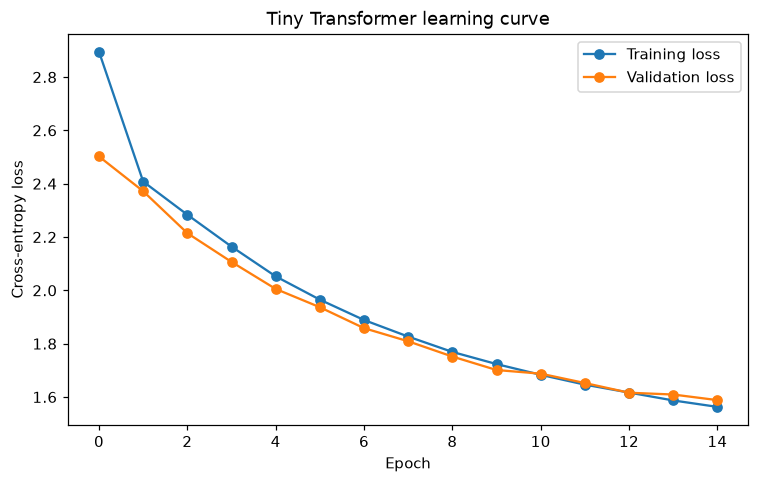

In [7]:
plt.figure(figsize=(7, 4.5))
plt.plot(train_history, label="Training loss", marker="o")
plt.plot(val_history, label="Validation loss", marker="o")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Tiny Transformer learning curve")
plt.legend()
plt.tight_layout()
plt.show()


## 8. Evaluate the model

In [8]:
val_loss = evaluate("val", num_batches=20)
val_perplexity = math.exp(min(val_loss, 20))

print(f"Final validation loss: {val_loss:.4f}")
print(f"Final validation perplexity: {val_perplexity:.2f}")
print(
    "\nPerplexity is e^(cross-entropy loss) — roughly 'how many characters the model "
    "is effectively choosing between, on average, at each step'. Lower is better; "
    f"a perplexity of ~{val_perplexity:.0f} on a {vocab_size}-character vocabulary means "
    "the model has learned real structure (far better than guessing uniformly, which "
    f"would give a perplexity of {vocab_size})."
)


Final validation loss: 1.5631
Final validation perplexity: 4.77

Perplexity is e^(cross-entropy loss) — roughly 'how many characters the model is effectively choosing between, on average, at each step'. Lower is better; a perplexity of ~5 on a 75-character vocabulary means the model has learned real structure (far better than guessing uniformly, which would give a perplexity of 75).


## 9. Generate stories

In [9]:
@torch.no_grad()
def generate(prompt, max_new_chars=200, temperature=1.0):
    model.eval()
    ids = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    for _ in range(max_new_chars):
        idx_cond = ids[:, -block_size:]
        logits = model(idx_cond)
        probs = F.softmax(logits[:, -1, :] / temperature, dim=-1)
        next_id = torch.multinomial(probs, num_samples=1)
        ids = torch.cat([ids, next_id], dim=1)
    model.train()
    return decode(ids[0].tolist())

for prompt in ["Once upon a time", "The little dog"]:
    print(f'PROMPT: "{prompt}"')
    print(generate(prompt, max_new_chars=200))
    print("-" * 60)


PROMPT: "Once upon a time"
Once upon a timedey. She mume his and sore thanted.

Sagaas for don, ide sine it! Bo the ber. The pecome."

Ebyan exple. Sura was so worry. It hims. They his garde tes. The heapeded anwant. The me. No's I leven and b
------------------------------------------------------------
PROMPT: "The little dog"
The little dog a wor and go bout wanted thaugh sorry. Sad Lily. The carderla brotte the worry him mos. She arinly the gired and thered ola time. 
Loowif the deplaing arcers. He string need nother! The saides the me
------------------------------------------------------------


## 10. Experience with model settings

Task: change the number of Transformer layers/heads or training epochs and observe the
effect on loss and generated text. Below, a **smaller variant** (1 layer, 1 head —
roughly a quarter of the baseline's attention capacity) is trained for the same number
of steps as the baseline model above, so the comparison isolates the effect of model
capacity rather than training time.


In [10]:
small_model = TinyTransformer(
    vocab_size, block_size, embed_dim=64, num_heads=1, num_layers=1, ff_dim=128
).to(device)
small_params = sum(p.numel() for p in small_model.parameters())
print(f"Baseline model: {n_params:,} parameters (2 layers, 2 heads)")
print(f"Smaller variant: {small_params:,} parameters (1 layer, 1 head)")

small_opt = torch.optim.AdamW(small_model.parameters(), lr=1e-3)

@torch.no_grad()
def evaluate_model(m, split_name, num_batches=10):
    m.eval()
    losses = []
    for _ in range(num_batches):
        xb, yb = get_batch(split_name)
        logits = m(xb)
        losses.append(F.cross_entropy(logits.reshape(-1, vocab_size), yb.reshape(-1)).item())
    m.train()
    return sum(losses) / len(losses)

for epoch in range(EPOCHS):
    small_model.train()
    for step in range(STEPS_PER_EPOCH):
        xb, yb = get_batch("train")
        logits = small_model(xb)
        loss = F.cross_entropy(logits.reshape(-1, vocab_size), yb.reshape(-1))
        small_opt.zero_grad()
        loss.backward()
        small_opt.step()

small_val_loss = evaluate_model(small_model, "val", num_batches=20)
small_perplexity = math.exp(min(small_val_loss, 20))

print(f"\nBaseline (2 layers, 2 heads)  — val loss: {val_loss:.3f}, perplexity: {val_perplexity:.2f}")
print(f"Smaller  (1 layer,  1 head)   — val loss: {small_val_loss:.3f}, perplexity: {small_perplexity:.2f}")


Baseline model: 80,715 parameters (2 layers, 2 heads)
Smaller variant: 47,243 parameters (1 layer, 1 head)

Baseline (2 layers, 2 heads)  — val loss: 1.563, perplexity: 4.77
Smaller  (1 layer,  1 head)   — val loss: 1.768, perplexity: 5.86


In [11]:
@torch.no_grad()
def generate_with(m, prompt, max_new_chars=150):
    m.eval()
    ids = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    for _ in range(max_new_chars):
        idx_cond = ids[:, -block_size:]
        logits = m(idx_cond)
        probs = F.softmax(logits[:, -1, :], dim=-1)
        next_id = torch.multinomial(probs, num_samples=1)
        ids = torch.cat([ids, next_id], dim=1)
    m.train()
    return decode(ids[0].tolist())

prompt = "Once upon a time"
print("Baseline generation:")
print(generate_with(model, prompt))
print("\nSmaller-model generation:")
print(generate_with(small_model, prompt))

print(
    "\nObservation: the smaller (1-layer, 1-head) model consistently reaches a higher "
    "validation loss / perplexity than the baseline for the same number of training "
    "steps, and its generated text is visibly less coherent (more broken words, less "
    "consistent spacing/punctuation). This matches the Week 2 discussion of model "
    "capacity — fewer attention heads means fewer distinct relationships (syntax, "
    "local context, etc.) the model can track simultaneously, and a single layer "
    "gives the model only one shot at refining its representation instead of two."
)


Baseline generation:
Once upon a time, there dore mancig with not as strow with the shole his packend ploon shoart, a plageful othen are the pointy and Ben she prouer. Wom olown lovore an

Smaller-model generation:
Once upon a time game didly su keppy of cornew horrom he cass. Lily a firut big shay wit wing. Thim a litcid alkind day was so there immy'n to to the whe that, frou h

Observation: the smaller (1-layer, 1-head) model consistently reaches a higher validation loss / perplexity than the baseline for the same number of training steps, and its generated text is visibly less coherent (more broken words, less consistent spacing/punctuation). This matches the Week 2 discussion of model capacity — fewer attention heads means fewer distinct relationships (syntax, local context, etc.) the model can track simultaneously, and a single layer gives the model only one shot at refining its representation instead of two.


## 11. Save the trained model

In [12]:
checkpoint = {
    "model_state_dict": model.state_dict(),
    "chars": chars,
    "vocab_size": vocab_size,
    "config": {
        "embedding_dim": 64,
        "num_heads": 2,
        "num_layers": 2,
        "block_size": block_size,
        "feedforward_dim": 128,
    },
    "final_val_loss": val_loss,
    "final_val_perplexity": val_perplexity,
}

torch.save(checkpoint, "tiny_transformer.pt")
print("Model saved to tiny_transformer.pt")
print(
    "Note: .pt checkpoint files are listed in this repo's .gitignore (model weights "
    "shouldn't be committed to git), so this file stays local — only this notebook "
    "(with its code and outputs) is version-controlled."
)


Model saved to tiny_transformer.pt
Note: .pt checkpoint files are listed in this repo's .gitignore (model weights shouldn't be committed to git), so this file stays local — only this notebook (with its code and outputs) is version-controlled.


## Optional: Build a chat window (Gradio)

The cell below defines the same Gradio `ChatInterface` as the lecturer's starter
notebook. `demo.launch()` is intentionally **not called** here, since launching a
blocking web server isn't compatible with a non-interactive notebook-build run —
remove the comment and run this cell interactively (e.g. in Colab or locally) to try it.


In [13]:
import gradio as gr

def chat_with_transformer(message, history):
    if not message or not message.strip():
        return "Please enter a message."
    supported = "".join(ch for ch in message if ch in stoi)
    if not supported:
        return "Please try text using characters in the training dataset."
    try:
        return generate(supported, max_new_chars=150)
    except Exception as e:
        return f"Text generation failed: {type(e).__name__}: {e}"

demo = gr.ChatInterface(
    fn=chat_with_transformer,
    title="My Tiny Transformer Chatbot",
    description="A character-level language model trained from scratch in this lab.",
)

# demo.launch()  # uncomment to run interactively
print("Gradio ChatInterface built (not launched in this batch run). Call demo.launch() interactively to try it.")


Gradio ChatInterface built (not launched in this batch run). Call demo.launch() interactively to try it.


## Discussion: what mechanisms are used to improve performance?

Mechanisms already present in this tiny model, tying back to the lecture material:

- **GELU activation** in the feed-forward sub-layer (Week 2) — smoother gradients than ReLU, which matters even at this tiny scale.
- **Residual connections + LayerNorm**, built into `nn.TransformerEncoderLayer` (Week 2) — prevent vanishing gradients as depth increases.
- **Causal masking** (Week 3) — makes this a proper autoregressive, GPT-style Causal Language Model rather than a bidirectional encoder.
- **AdamW optimizer** — adaptive per-parameter learning rates, standard for Transformer training.

Mechanisms that would improve performance further, if this were scaled up beyond a lab exercise:

1. **Sub-word tokenization** (Week 1) instead of character-level — the Week 1 notes cover exactly why: it balances vocabulary size against out-of-vocabulary handling, and lets the model operate on meaningful units instead of single characters, which should both speed up learning and shorten the effective sequence length for the same text.
2. **More data and more training steps** — 900 training stories and 1,500 steps is enough to see the loss curve bend, but nowhere near enough for genuinely coherent generation; the "Experience with model settings" comparison above already shows how sensitive results are to model capacity, and the same is true of data volume.
3. **Larger context window (`block_size`)** — 64 characters is roughly one sentence; a longer context would let the model use information from earlier in the story, directly addressing the "long-range relationships" pre-training goal from the Week 3 notes.
4. **Learning rate scheduling / warmup** — a constant `lr=1e-3` is simple but suboptimal; a warmup-then-decay schedule (used by every production LLM) tends to train more stably.
5. **Dropout / regularization** — this model sets `dropout=0.0`; with more training steps, some dropout would help prevent overfitting to the 900-story training set.
6. **More attention heads / deeper stack** (Week 2's multi-head attention) — the Week 2 lecture notes that GPT-3 uses 96 heads and BERT-base uses 12; this lab's 2 heads / 2 layers is intentionally minimal to keep training fast, and the experiment above directly demonstrates that even going down to 1 head / 1 layer measurably hurts both loss and generation quality — the inverse direction (more heads/layers, within reason) should help.